In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

np.random.seed(42)
tf.random.set_seed(42)

In [2]:
dados = fetch_california_housing(as_frame=True)
df = dados.frame

print("Formato do dataset (linhas, colunas):", df.shape)
print("\nValores nulos por coluna:")
print(df.isnull().sum())
df.head()

Formato do dataset (linhas, colunas): (20640, 9)

Valores nulos por coluna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


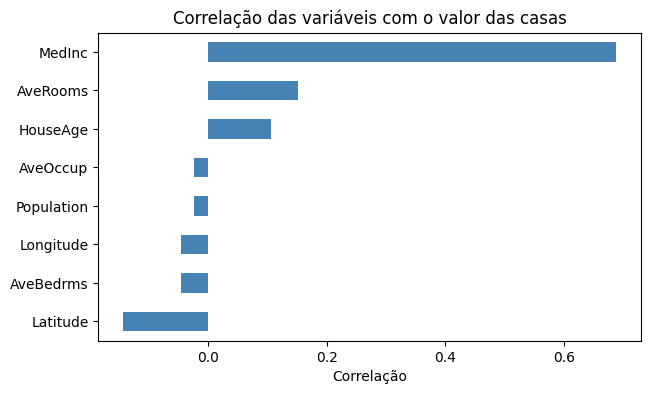

In [3]:

correlacao = df.corr()["MedHouseVal"].drop("MedHouseVal").sort_values()

correlacao.plot(kind="barh", figsize=(7, 4), color="steelblue")
plt.title("Correlação das variáveis com o valor das casas")
plt.xlabel("Correlação")
plt.show()

In [4]:
X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Treino:", X_treino.shape)
print("Teste: ", X_teste.shape)

Treino: (16512, 8)
Teste:  (4128, 8)


In [5]:
scaler = StandardScaler()
X_treino_esc = scaler.fit_transform(X_treino)
X_teste_esc = scaler.transform(X_teste)

In [6]:
modelo = keras.Sequential([
    keras.Input(shape=(X_treino_esc.shape[1],)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(1),
])

modelo.compile(optimizer="adam", loss="mse", metrics=["mae"])
modelo.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,689 (10.50 KB)

 Trainable params: 2,689 (10.50 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
parada_antecipada = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)

historico = modelo.fit(
    X_treino_esc, y_treino,
    validation_split=0.2,
    epochs=100,
    batch_size=32,
    callbacks=[parada_antecipada],
    verbose=1,
)

Epoch 1/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - loss: 0.9449 - mae: 0.6723 - val_loss: 0.4838 - val_mae: 0.5051
Epoch 2/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - loss: 0.4105 - mae: 0.4581 - val_loss: 0.4209 - val_mae: 0.4702
Epoch 3/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.3753 - mae: 0.4359 - val_loss: 0.4006 - val_mae: 0.4563
Epoch 4/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3584 - mae: 0.4238 - val_loss: 0.3898 - val_mae: 0.4490
Epoch 5/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3490 - mae: 0.4158 - val_loss: 0.3835 - val_mae: 0.4420
Epoch 6/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3404 - mae: 0.4091 - val_loss: 0.3922 - val_mae: 0.4401
Epoch 7/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3320 - mae: 0.4024 - val_loss: 0.3530 - val_mae: 0.4257
Epoch 8/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.3178 - mae: 0.3949 - val_loss: 0.3497 - val_mae: 0.4202
Epoch 9/100
413/413 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/

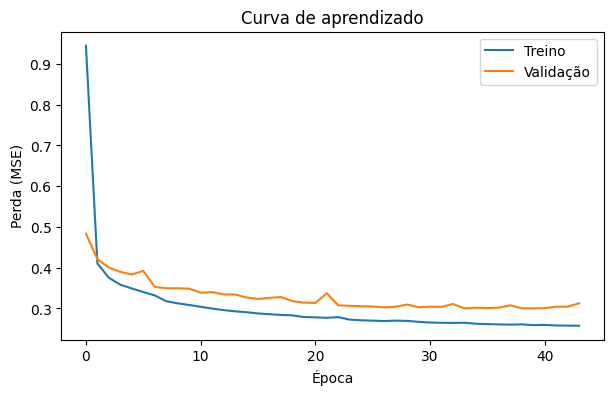

In [8]:
plt.figure(figsize=(7, 4))
plt.plot(historico.history["loss"], label="Treino")
plt.plot(historico.history["val_loss"], label="Validação")
plt.xlabel("Época")
plt.ylabel("Perda (MSE)")
plt.title("Curva de aprendizado")
plt.legend()
plt.show()

In [9]:
modelo_linear = LinearRegression()
modelo_linear.fit(X_treino_esc, y_treino)

def avaliar(nome, previsoes):
    return {
        "Modelo": nome,
        "MAE": mean_absolute_error(y_teste, previsoes),
        "RMSE": np.sqrt(mean_squared_error(y_teste, previsoes)),
        "R²": r2_score(y_teste, previsoes),
    }

previsoes_rn = modelo.predict(X_teste_esc, verbose=0).ravel()
previsoes_lin = modelo_linear.predict(X_teste_esc)

resultados = pd.DataFrame([
    avaliar("Regressão Linear (baseline)", previsoes_lin),
    avaliar("Rede Neural (MLP)", previsoes_rn),
]).set_index("Modelo").round(3)

resultados

,MAE,RMSE,R²
Modelo,,,
Regressão Linear (baseline),0.533,0.746,0.576
Rede Neural (MLP),0.374,0.538,0.779


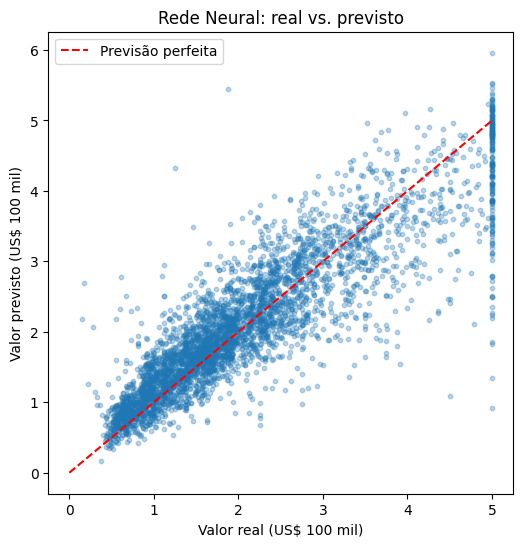

In [10]:
plt.figure(figsize=(6, 6))
plt.scatter(y_teste, previsoes_rn, alpha=0.3, s=10)
plt.plot([0, 5], [0, 5], color="red", linestyle="--", label="Previsão perfeita")
plt.xlabel("Valor real (US$ 100 mil)")
plt.ylabel("Valor previsto (US$ 100 mil)")
plt.title("Rede Neural: real vs. previsto")
plt.legend()
plt.show()

In [11]:
exemplo = X_teste.iloc[[0]]
exemplo_esc = scaler.transform(exemplo)
previsao = modelo.predict(exemplo_esc, verbose=0)[0][0]

print("Características do bairro:")
print(exemplo.T)
print()
print(f"Valor previsto: US$ {previsao * 100000:,.0f}")
print(f"Valor real:     US$ {y_teste.iloc[0] * 100000:,.0f}")

Características do bairro:
                  20046
MedInc         1.681200
HouseAge      25.000000
AveRooms       4.192201
AveBedrms      1.022284
Population  1392.000000
AveOccup       3.877437
Latitude      36.060000
Longitude   -119.010000

Valor previsto: US$ 39,654
Valor real:     US$ 47,700
